Build comprehensive and interactive dashboards integrating multiple advanced data visualizations in Plotly or Tableau, automating updates with live data streams for real-time business intelligence.

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

In [3]:
class LiveDataStreamer:
    def __init__(self):
        self.regions = ['North America', 'Europe', 'Asia-Pacific']
        self.categories = ['Electronics', 'Apparel', 'Home & Kitchen']
        
    def fetch_latest_batch(self, batch_size=20):
        """Simulate real-time incoming streaming records."""
        now = pd.Timestamp.now()
        dates = [now - pd.Timedelta(seconds=i*5) for i in range(batch_size)]
        
        return pd.DataFrame({
            'timestamp': dates,
            'region': np.random.choice(self.regions, size=batch_size),
            'category': np.random.choice(self.categories, size=batch_size),
            'sales': np.random.uniform(50, 500, size=batch_size).round(2),
            'margin': np.random.uniform(0.1, 0.45, size=batch_size).round(2)
        })

In [4]:
streamer = LiveDataStreamer()
initial_data = streamer.fetch_latest_batch(50)

In [5]:
print(initial_data.head())

                   timestamp         region     category   sales  margin
0 2026-10-23 11:40:18.531733   Asia-Pacific      Apparel  139.42    0.41
1 2026-10-23 11:40:13.531733  North America  Electronics   52.48    0.21
2 2026-10-23 11:40:08.531733   Asia-Pacific      Apparel  416.96    0.14
3 2026-10-23 11:40:03.531733   Asia-Pacific  Electronics  368.09    0.18
4 2026-10-23 11:39:58.531733  North America      Apparel  378.05    0.25


In [6]:
from IPython.display import display, clear_output

In [7]:
stream_buffer = initial_data.copy()

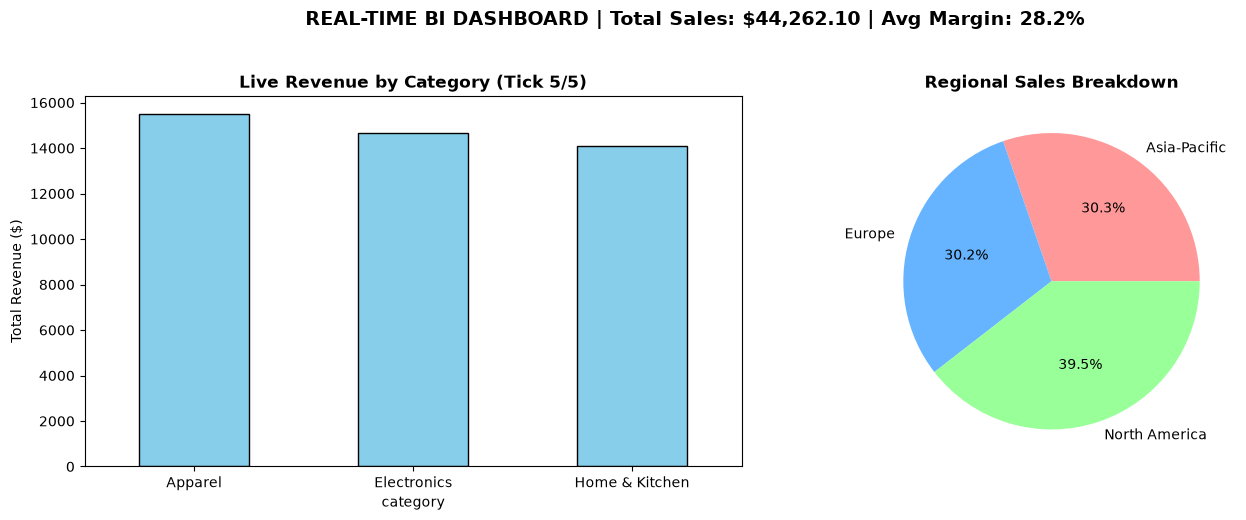

In [10]:
for tick in range(5):
    new_records = streamer.fetch_latest_batch(batch_size=10)
    stream_buffer = pd.concat([stream_buffer, new_records], ignore_index=True)
    kpi_total_sales = stream_buffer['sales'].sum()
    kpi_avg_margin = stream_buffer['margin'].mean() * 100
    category_summary = stream_buffer.groupby('category')['sales'].sum()
    region_summary = stream_buffer.groupby('region')['sales'].sum()
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    category_summary.plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
    axes[0].set_title(f'Live Revenue by Category (Tick {tick+1}/5)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Total Revenue ($)')
    axes[0].tick_params(axis='x', rotation=0)
    
    region_summary.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'])
    axes[1].set_title('Regional Sales Breakdown', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('')
    
    plt.suptitle(
        f"REAL-TIME BI DASHBOARD | Total Sales: ${kpi_total_sales:,.2f} | Avg Margin: {kpi_avg_margin:.1f}%",
        fontsize=14, fontweight='bold', y=1.03
    )
    plt.tight_layout()
    display(fig)
    plt.close(fig)
    
    time.sleep(1)

In [14]:
from dash import Dash, dcc, html, Input, Output


In [15]:
app = Dash(__name__)

In [16]:
live_db = streamer.fetch_latest_batch(100)

In [17]:
app.layout = html.Div([
    html.H2("Automated Real-Time BI Dashboard", style={'textAlign': 'center', 'fontFamily': 'Arial'}),
    
    # Metric KPI Display Cards
    html.Div(id='kpi-cards', style={'display': 'flex', 'justifyContent': 'space-around', 'padding': '10px'}),
    
    # Dual Real-Time Visual Charts
    html.Div([
        dcc.Graph(id='live-time-series', style={'width': '50%', 'display': 'inline-block'}),
        dcc.Graph(id='live-category-bar', style={'width': '50%', 'display': 'inline-block'})
    ]),
    
    # Dynamic Auto-Refresh Interval Component (Updates every 2000 ms)
    dcc.Interval(id='stream-interval', interval=2000, n_intervals=0)
])

In [28]:
@app.callback(
    [Output('kpi-cards', 'children'),
     Output('live-time-series', 'figure'),
     Output('live-category-bar', 'figure')],
    Input('stream-interval', 'n_intervals')
)
def update_dashboard_live(n):
    global live_db
    
    new_data = streamer.fetch_latest_batch(5)
    live_db = pd.concat([live_db, new_data], ignore_index=True).tail(200)
    
    total_sales = live_db['sales'].sum()
    avg_margin = live_db['margin'].mean() * 100
    
    kpis = [
        html.Div([html.H4("Live Revenue"), html.H3(f"${total_sales:,.2f}")], 
                 style={'background': '#f4f4f4', 'padding': '15px', 'borderRadius': '8px'}),
        html.Div([html.H4("Avg Profit Margin"), html.H3(f"{avg_margin:.1f}%")], 
                 style={'background': '#f4f4f4', 'padding': '15px', 'borderRadius': '8px'})
    ]
    
    time_fig = {
        'data': [{'x': live_db['timestamp'], 'y': live_db['sales'], 'type': 'line', 'name': 'Sales'}],
        'layout': {'title': 'Live Sales Stream Trajectory', 'xaxis': {'title': 'Timestamp'}, 'yaxis': {'title': 'Sales ($)'}}
    }
    
    cat_data = live_db.groupby('category')['sales'].sum().reset_index()
    cat_fig = {
        'data': [{'x': cat_data['category'], 'y': cat_data['sales'], 'type': 'bar', 'marker': {'color': '#66b3ff'}}],
        'layout': {'title': 'Revenue by Category', 'xaxis': {'title': 'Category'}, 'yaxis': {'title': 'Sales ($)'}}
    }
    
    return kpis, time_fig, cat_fig

In [29]:
print("Real-time BI Dashboard code configured! Uncomment app.run() to activate local streaming server.")

Real-time BI Dashboard code configured! Uncomment app.run() to activate local streaming server.
